country
US         168
India       81
UK          54
Unknown     43
Canada      18
Spain       17
France      16
Brazil      16
Mexico      13
Germany     11
Name: count, dtype: int64
listed_in
Reality TV                  60
Kids' TV                    53
Stand-Up Comedy             52
Comedies                    51
British TV Shows            50
Children & Family Movies    49
International Movies        45
Sci-Fi & Fantasy            44
Documentaries               44
Thrillers                   44
Name: count, dtype: int64


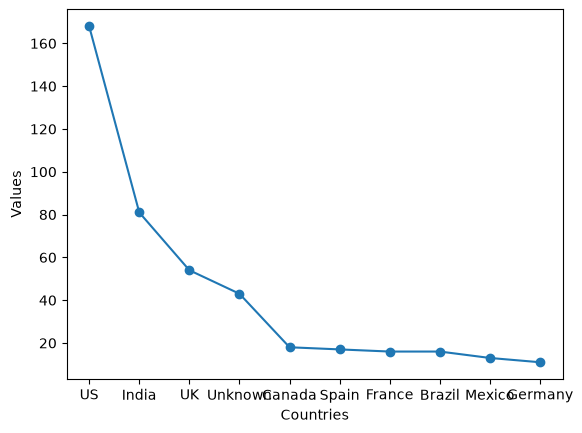

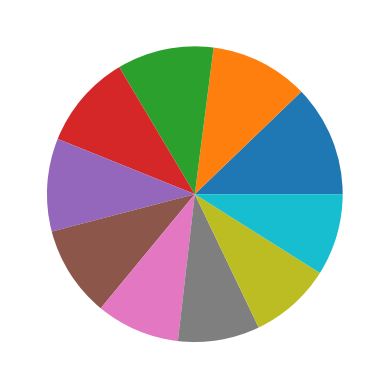

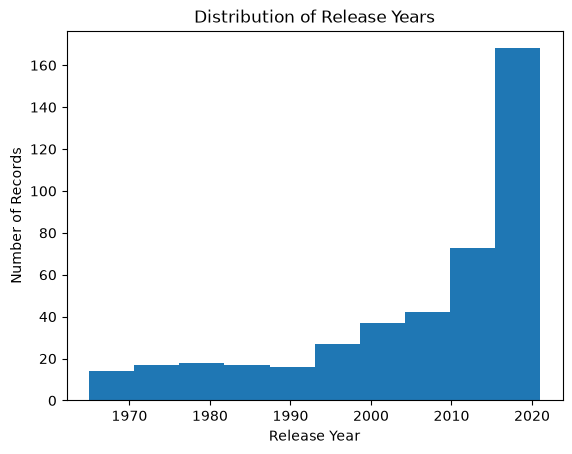

Number of rows: 429
Number of columns: 10
show_id           0
type              0
title             0
director        136
country          45
date_added        8
release_year      0
rating            6
duration          0
listed_in         0
dtype: int64
show_id          0.000000
type             0.000000
title            0.000000
director        31.701632
country         10.489510
date_added       1.864802
release_year     0.000000
rating           1.398601
duration         0.000000
listed_in        0.000000
dtype: float64


In [10]:
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
data = pd.read_csv("netflix_titles.csv")
original_data = pd.read_csv("netflix_titles.csv")
#For missing values
data.fillna({"director": "Unknown","country": "Unknown","rating": "Unknown"}, inplace=True)
original_data["show_id"].duplicated().sum()
data.drop_duplicates(subset=["show_id"],inplace=True)
missing_indexes= data[data["date_added"].isnull()].index
for index in missing_indexes:
    data.loc[index, "date_added"] = "April 26, 2022"

country_mapping = {
    "USA": "US",
    "U.S.A.": "US",
    "United States": "US",
    "United Kingdom": "UK",
    "U.K.": "UK",
    "S. Korea": "South Korea"
}

def clean_countries(country):
    cleaned = []

    for country in country:
        country = country_mapping.get(country, country)
        cleaned.append(country)

    return ", ".join(cleaned)
data["country"] = data["country"].str.split(", ")
data["country"] = data["country"].apply(clean_countries)

# For country analysis
countries = data["country"].str.split(", ")
countries = countries.explode()
top_countries = countries.value_counts().head(10)
print(top_countries)
categories = data["listed_in"].str.split(", ")
categories = categories.explode()
top_categories = categories.value_counts().head(10)
print(top_categories)
x = top_countries.index
y = top_countries.values
xaxis = top_categories.index
yaxis = top_categories.values
plt.plot(x,y , marker ="o")
plt.xlabel("Countries")
plt.ylabel("Values")
plt.show()
plt.pie( yaxis)
plt.show()
plt.hist(data["release_year"])
plt.xlabel("Release Year")
plt.ylabel("Number of Records")
plt.title("Distribution of Release Years")
plt.show()
print("Number of rows:", len(data))
print("Number of columns:", len(data.columns))
sum =original_data.isnull().sum()
per = (sum/len(data))*100 
print(sum)
print(per)  
#print(data)
data.to_csv("netflix_titles_cleaned.csv", index=False)



